<a href="https://colab.research.google.com/github/sabbirpuspo/LearningforMe/blob/main/Credit_Card_Fraud_Detection_Assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Task: Credit Card Fraud Detection

Dataset: Kaggle — Credit Card Fraud Detection

Kaggle Link: https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud


Student Name: Md Sabbir Hosen

Date: 10-11-2026

In [7]:

!pip -q install kagglehub numba

import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score, confusion_matrix
)

# Load dataset
path = kagglehub.dataset_download("mlg-ulb/creditcardfraud")
df = pd.read_csv(Path(path) / "creditcard.csv")

X = df.drop(columns=["Class"]).values
y = df["Class"].astype(int).values

print(f"Total samples: {len(X)}")
print(f"Fraud: {sum(y)}, Legitimate: {len(y) - sum(y)}")

# Train / test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Standardize features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("\nData ready!")
print(f"Training samples: {len(X_train)}")
print(f"Testing samples: {len(X_test)}")


Using Colab cache for faster access to the 'creditcardfraud' dataset.
Total samples: 284807
Fraud: 492, Legitimate: 284315

Data ready!
Training samples: 227845
Testing samples: 56962


In [8]:

import numpy as np
from numba import njit

@njit
def train_sgd(X, y_signed, lr, epochs, seed):
    np.random.seed(seed)

    n_samples, n_features = X.shape
    weights = np.zeros(n_features)
    bias = 0.0

    for epoch in range(epochs):
        order = np.random.permutation(n_samples)

        for i in order:
            score = bias

            for j in range(n_features):
                score += X[i, j] * weights[j]

            if y_signed[i] * score <= 0:
                for j in range(n_features):
                    weights[j] += lr * y_signed[i] * X[i, j]

                bias += lr * y_signed[i]

    return weights, bias


class Perceptron:
    def __init__(self, lr=0.1, epochs=50, mode='batch'):
        self.lr = lr
        self.epochs = epochs
        self.mode = mode

    def fit(self, X, y):
        X = np.ascontiguousarray(X, dtype=np.float64)
        y_signed = np.where(y == 1, 1, -1)

        n_samples, n_features = X.shape
        self.weights = np.zeros(n_features)
        self.bias = 0.0

        if self.mode == 'batch':
            for epoch in range(self.epochs):
                scores = X @ self.weights + self.bias
                mistakes = (y_signed * scores <= 0)

                if not np.any(mistakes):
                    break

                self.weights += (
                    self.lr *
                    (X[mistakes].T @ y_signed[mistakes])
                    / n_samples
                )

                self.bias += (
                    self.lr *
                    np.sum(y_signed[mistakes])
                    / n_samples
                )

        elif self.mode in ('sgd', 'stochastic'):
            self.weights, self.bias = train_sgd(
                X, y_signed, self.lr, self.epochs, 42
            )

        else:
            raise ValueError("Choose 'batch' or 'sgd'")

        return self

    def predict(self, X):
        scores = X @ self.weights + self.bias
        return (scores >= 0).astype(int)

print("Perceptron class ready!")


Perceptron class ready!


In [9]:

# ── Train with Batch Gradient Descent ──
print("=" * 50)
print("Training with BATCH Gradient Descent")
print("=" * 50)

model_batch = Perceptron(lr=0.1, epochs=50, mode='batch')
model_batch.fit(X_train, y_train)

y_pred_batch = model_batch.predict(X_test)
acc_batch = accuracy_score(y_test, y_pred_batch)
prec_batch = precision_score(y_test, y_pred_batch, zero_division=0)
rec_batch = recall_score(y_test, y_pred_batch, zero_division=0)
f1_batch = f1_score(y_test, y_pred_batch, zero_division=0)

print(f"\nTest Accuracy : {acc_batch * 100:.2f}%")
print(f"Precision     : {prec_batch * 100:.2f}%")
print(f"Recall        : {rec_batch * 100:.2f}%")
print(f"F1-Score      : {f1_batch * 100:.2f}%")
print(f"\nCorrect: {sum(y_pred_batch == y_test)}/{len(y_test)}")


# ── Train with Stochastic Gradient Descent ──
print("\n" + "=" * 50)
print("Training with STOCHASTIC Gradient Descent")
print("=" * 50)

model_sgd = Perceptron(lr=0.1, epochs=50, mode='sgd')
model_sgd.fit(X_train, y_train)

y_pred_sgd = model_sgd.predict(X_test)
acc_sgd = accuracy_score(y_test, y_pred_sgd)
prec_sgd = precision_score(y_test, y_pred_sgd, zero_division=0)
rec_sgd = recall_score(y_test, y_pred_sgd, zero_division=0)
f1_sgd = f1_score(y_test, y_pred_sgd, zero_division=0)

print(f"\nTest Accuracy : {acc_sgd * 100:.2f}%")
print(f"Precision     : {prec_sgd * 100:.2f}%")
print(f"Recall        : {rec_sgd * 100:.2f}%")
print(f"F1-Score      : {f1_sgd * 100:.2f}%")
print(f"\nCorrect: {sum(y_pred_sgd == y_test)}/{len(y_test)}")


Training with BATCH Gradient Descent

Test Accuracy : 99.90%
Precision     : 75.90%
Recall        : 64.29%
F1-Score      : 69.61%

Correct: 56907/56962

Training with STOCHASTIC Gradient Descent

Test Accuracy : 99.93%
Precision     : 78.22%
Recall        : 80.61%
F1-Score      : 79.40%

Correct: 56921/56962


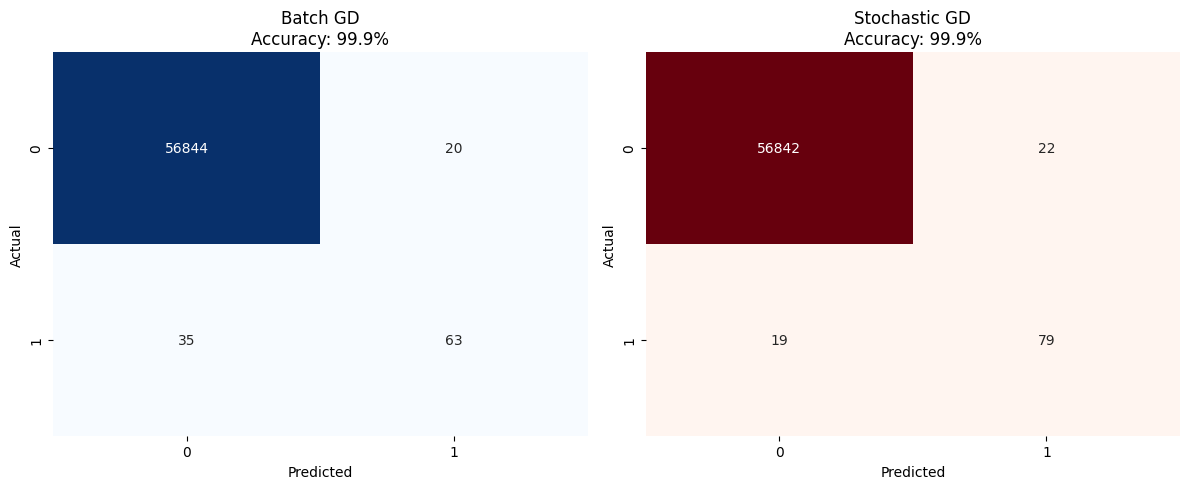


COMPARISON: Batch GD vs Stochastic GD
Metric                           Batch GD        Stochastic GD
----------------------------------------------------------------------
Accuracy                           99.90%               99.93%
Precision                          75.90%               78.22%
Recall                             64.29%               80.61%
F1-Score                           69.61%               79.40%
Batch GD: Detected 63 of 98 frauds
SGD:      Detected 79 of 98 frauds
Training complete!


In [10]:

# ── Visualize: Confusion Matrices side by side ──
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_batch = confusion_matrix(y_test, y_pred_batch, labels=[0, 1])
sns.heatmap(cm_batch, annot=True, fmt='d',
            cmap='Blues', ax=axes[0], cbar=False)
axes[0].set_title(f'Batch GD\nAccuracy: {acc_batch * 100:.1f}%',
                  fontsize=12)
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

cm_sgd = confusion_matrix(y_test, y_pred_sgd, labels=[0, 1])
sns.heatmap(cm_sgd, annot=True, fmt='d',
            cmap='Reds', ax=axes[1], cbar=False)
axes[1].set_title(f'Stochastic GD\nAccuracy: {acc_sgd * 100:.1f}%',
                  fontsize=12)
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Actual')

plt.tight_layout()
plt.show()

# ── Print comparison table ──
print("\n" + "=" * 70)
print("COMPARISON: Batch GD vs Stochastic GD")
print("=" * 70)

print(f"{'Metric':<20} {'Batch GD':>20} {'Stochastic GD':>20}")
print("-" * 70)

print(f"{'Accuracy':<20} {acc_batch * 100:>19.2f}% {acc_sgd * 100:>19.2f}%")
print(f"{'Precision':<20} {prec_batch * 100:>19.2f}% {prec_sgd * 100:>19.2f}%")
print(f"{'Recall':<20} {rec_batch * 100:>19.2f}% {rec_sgd * 100:>19.2f}%")
print(f"{'F1-Score':<20} {f1_batch * 100:>19.2f}% {f1_sgd * 100:>19.2f}%")

print("=" * 70)

# Fraud detection details
print(f"Batch GD: Detected {cm_batch[1,1]} of {sum(y_test)} frauds")
print(f"SGD:      Detected {cm_sgd[1,1]} of {sum(y_test)} frauds")

print("Training complete!")
print("=" * 70)


In [11]:

import time
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    average_precision_score,
    confusion_matrix
)

results = []

# Warm up Numba compilation outside the timing measurement
if 'train_sgd' in globals():
    _ = train_sgd(
        np.zeros((4, X_train.shape[1]), dtype=np.float64),
        np.array([-1, 1, -1, 1], dtype=np.int64),
        0.1, 1, 42
    )

for mode, name in [
    ('batch', 'Batch GD'),
    ('sgd', 'Stochastic GD')
]:
    print(f"\nTraining {name}...")

    model = Perceptron(lr=0.1, epochs=50, mode=mode)

    # Measure training time
    start = time.perf_counter()
    model.fit(X_train, y_train)
    training_time = time.perf_counter() - start

    # Predictions
    y_pred = model.predict(X_test)
    scores = X_test @ model.weights + model.bias

    # Confusion matrix
    tn, fp, fn, tp = confusion_matrix(
        y_test, y_pred, labels=[0, 1]
    ).ravel()

    results.append({
        'Method': name,
        'Training Time (s)': training_time,
        'Accuracy (%)': accuracy_score(y_test, y_pred) * 100,
        'Precision (%)': precision_score(
            y_test, y_pred, zero_division=0
        ) * 100,
        'Recall (%)': recall_score(
            y_test, y_pred, zero_division=0
        ) * 100,
        'F1-Score (%)': f1_score(
            y_test, y_pred, zero_division=0
        ) * 100,
        'Balanced Accuracy (%)': balanced_accuracy_score(
            y_test, y_pred
        ) * 100,
        'PR-AUC': average_precision_score(y_test, scores),
        'Frauds Detected': tp,
        'Missed Frauds': fn
    })

# Display comparison
comparison_df = pd.DataFrame(results)

print("\n" + "=" * 75)
print("CREDIT CARD FRAUD DETECTION - PERFORMANCE COMPARISON")
print("=" * 75)

print(comparison_df.round(4).to_string(index=False))

# Identify faster training method
fastest = comparison_df.loc[
    comparison_df['Training Time (s)'].idxmin(), 'Method'
]

print(f"\nFaster training time: {fastest}")
print("Note: training time does not establish convergence speed.")

print("\n✅ Comparison complete!")



Training Batch GD...

Training Stochastic GD...

CREDIT CARD FRAUD DETECTION - PERFORMANCE COMPARISON
       Method  Training Time (s)  Accuracy (%)  Precision (%)  Recall (%)  F1-Score (%)  Balanced Accuracy (%)  PR-AUC  Frauds Detected  Missed Frauds
     Batch GD             0.4289       99.9034        75.9036     64.2857       69.6133                82.1253  0.7296               63             35
Stochastic GD             1.4694       99.9280        78.2178     80.6122       79.3970                90.2868  0.6710               79             19

Faster training time: Batch GD
Note: training time does not establish convergence speed.

✅ Comparison complete!


Training samples: 182276
Validation samples: 45569


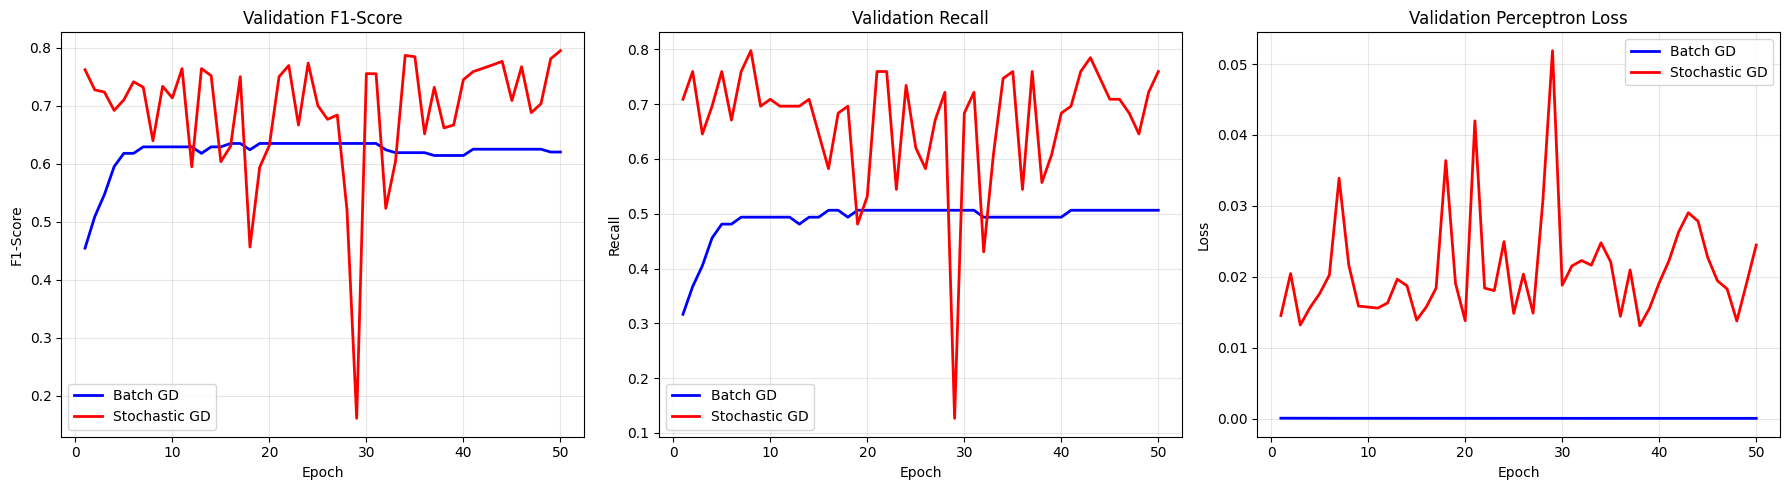


CONVERGENCE ANALYSIS: BATCH GD VS STOCHASTIC GD
Metric                             Batch GD             SGD
-----------------------------------------------------------------
Training Time (s)                    0.3258          1.1716
Final Validation F1                  0.6202          0.7947
Best Validation F1                   0.6349          0.7947
Final Validation Recall              0.5063          0.7595
Final Validation Loss                0.0000          0.0245

95% of highest observed Validation F1: 0.7550
Batch GD first reaches target: None
SGD first reaches target     : 1

✅ Convergence analysis complete!


In [13]:

import numpy as np
import matplotlib.pyplot as plt
import time

from numba import njit
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import f1_score, recall_score

# Configuration
LR = 0.1
EPOCHS = 50
SEED = 42

# ------------------------------------------------------------
# 1. Create a training/validation split
#    Keep the original test data untouched
# ------------------------------------------------------------

X_dev_raw, _, y_dev_all, _ = train_test_split(
    X, y, test_size=0.2,
    random_state=42, stratify=y
)

X_tr_raw, X_val_raw, y_tr, y_val = train_test_split(
    X_dev_raw, y_dev_all,
    test_size=0.2,
    random_state=42,
    stratify=y_dev_all
)

val_scaler = StandardScaler()

X_tr = np.ascontiguousarray(
    val_scaler.fit_transform(X_tr_raw),
    dtype=np.float64
)

X_val = np.ascontiguousarray(
    val_scaler.transform(X_val_raw),
    dtype=np.float64
)

y_signed = np.where(y_tr == 1, 1, -1)
y_val_signed = np.where(y_val == 1, 1, -1)

print("Training samples:", len(X_tr))
print("Validation samples:", len(X_val))

# ------------------------------------------------------------
# 2. Batch Gradient Descent: record weights each epoch
# ------------------------------------------------------------

n_samples, n_features = X_tr.shape

w_batch = np.zeros(n_features)
b_batch = 0.0

batch_weights = np.zeros((EPOCHS, n_features))
batch_biases = np.zeros(EPOCHS)

start = time.perf_counter()

for epoch in range(EPOCHS):

    scores = X_tr @ w_batch + b_batch
    mistakes = (y_signed * scores <= 0)

    if np.any(mistakes):
        w_batch += (
            LR * (X_tr[mistakes].T @ y_signed[mistakes])
            / n_samples
        )
        b_batch += (
            LR * np.sum(y_signed[mistakes])
            / n_samples
        )

    batch_weights[epoch] = w_batch.copy()
    batch_biases[epoch] = b_batch

batch_time = time.perf_counter() - start

# ------------------------------------------------------------
# 3. Stochastic GD: record weights each epoch
# ------------------------------------------------------------

@njit
def sgd_history(X, y, lr, epochs, seed):

    np.random.seed(seed)

    n, d = X.shape
    w = np.zeros(d)
    b = 0.0

    weights_history = np.zeros((epochs, d))
    biases_history = np.zeros(epochs)

    for epoch in range(epochs):

        order = np.random.permutation(n)

        for i in order:

            score = b

            for j in range(d):
                score += X[i, j] * w[j]

            if y[i] * score <= 0:

                for j in range(d):
                    w[j] += lr * y[i] * X[i, j]

                b += lr * y[i]

        weights_history[epoch, :] = w
        biases_history[epoch] = b

    return weights_history, biases_history


# Compile Numba before measuring training time
_ = sgd_history(
    np.zeros((4, n_features)),
    np.array([-1, 1, -1, 1]),
    LR, 1, SEED
)

start = time.perf_counter()

sgd_weights, sgd_biases = sgd_history(
    X_tr, y_signed, LR, EPOCHS, SEED
)

sgd_time = time.perf_counter() - start

# ------------------------------------------------------------
# 4. Evaluate validation performance each epoch
# ------------------------------------------------------------

def evaluate_history(weights_history, biases_history):

    f1_history = []
    recall_history = []
    loss_history = []

    for epoch in range(EPOCHS):

        scores = (
            X_val @ weights_history[epoch]
            + biases_history[epoch]
        )

        predictions = (scores >= 0).astype(int)

        f1_history.append(
            f1_score(y_val, predictions, zero_division=0)
        )

        recall_history.append(
            recall_score(y_val, predictions, zero_division=0)
        )

        loss_history.append(
            np.maximum(0, -y_val_signed * scores).mean()
        )

    return (
        np.array(f1_history),
        np.array(recall_history),
        np.array(loss_history)
    )


batch_f1, batch_recall, batch_loss = evaluate_history(
    batch_weights, batch_biases
)

sgd_f1, sgd_recall, sgd_loss = evaluate_history(
    sgd_weights, sgd_biases
)

# ------------------------------------------------------------
# 5. Plot convergence graphs
# ------------------------------------------------------------

epochs = np.arange(1, EPOCHS + 1)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# F1-Score
axes[0].plot(epochs, batch_f1, label="Batch GD",
             color="blue", linewidth=2)
axes[0].plot(epochs, sgd_f1, label="Stochastic GD",
             color="red", linewidth=2)
axes[0].set_title("Validation F1-Score")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("F1-Score")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Recall
axes[1].plot(epochs, batch_recall, label="Batch GD",
             color="blue", linewidth=2)
axes[1].plot(epochs, sgd_recall, label="Stochastic GD",
             color="red", linewidth=2)
axes[1].set_title("Validation Recall")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Recall")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

# Perceptron loss
axes[2].plot(epochs, batch_loss, label="Batch GD",
             color="blue", linewidth=2)
axes[2].plot(epochs, sgd_loss, label="Stochastic GD",
             color="red", linewidth=2)
axes[2].set_title("Validation Perceptron Loss")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("Loss")
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 6. Print convergence summary
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("CONVERGENCE ANALYSIS: BATCH GD VS STOCHASTIC GD")
print("=" * 65)

print(f"{'Metric':<27} {'Batch GD':>15} {'SGD':>15}")
print("-" * 65)

print(f"{'Training Time (s)':<27} {batch_time:>15.4f} {sgd_time:>15.4f}")
print(f"{'Final Validation F1':<27} {batch_f1[-1]:>15.4f} {sgd_f1[-1]:>15.4f}")
print(f"{'Best Validation F1':<27} {max(batch_f1):>15.4f} {max(sgd_f1):>15.4f}")
print(f"{'Final Validation Recall':<27} {batch_recall[-1]:>15.4f} {sgd_recall[-1]:>15.4f}")
print(f"{'Final Validation Loss':<27} {batch_loss[-1]:>15.4f} {sgd_loss[-1]:>15.4f}")

# Common threshold: 95% of the best F1 reached by either method
target = 0.95 * max(max(batch_f1), max(sgd_f1))

def first_target_epoch(history, target):
    indices = np.where(history >= target)[0]
    return int(indices[0] + 1) if len(indices) else None

batch_target = first_target_epoch(batch_f1, target)
sgd_target = first_target_epoch(sgd_f1, target)

print(f"\n95% of highest observed Validation F1: {target:.4f}")
print(f"Batch GD first reaches target: {batch_target}")
print(f"SGD first reaches target     : {sgd_target}")

print("\n✅ Convergence analysis complete!")


FINAL EXPERIMENT: Credit Card Fraud - Batch GD vs. Stochastic GD
Samples: 284,807 | Development: 227,845 | Test: 56,962 | Test fraud: 98
Model selection uses only development/validation data; test is excluded.
Batch GD         LR=0.001  | best mean val F1=0.7263 at epoch 23
Batch GD         LR=0.01   | best mean val F1=0.7263 at epoch 23
Batch GD         LR=0.1    | best mean val F1=0.7263 at epoch 23
Batch GD         LR=1      | best mean val F1=0.7263 at epoch 23
Stochastic GD    LR=0.001  | best mean val F1=0.8084 at epoch 5
Stochastic GD    LR=0.01   | best mean val F1=0.8084 at epoch 5
Stochastic GD    LR=0.1    | best mean val F1=0.8084 at epoch 5
Stochastic GD    LR=1      | best mean val F1=0.8084 at epoch 5

FINAL TEST RESULTS - validation-tuned, threshold fixed at score >= 0
       Method  Learning Rate  Epochs  Train Time (s)  Accuracy (%)  Precision (%)  Recall (%)  F1 (%)  Balanced Accuracy (%)  PR-AUC (Avg Precision)  ROC-AUC  Fraud Detected (TP)  Fraud Missed (FN)  False

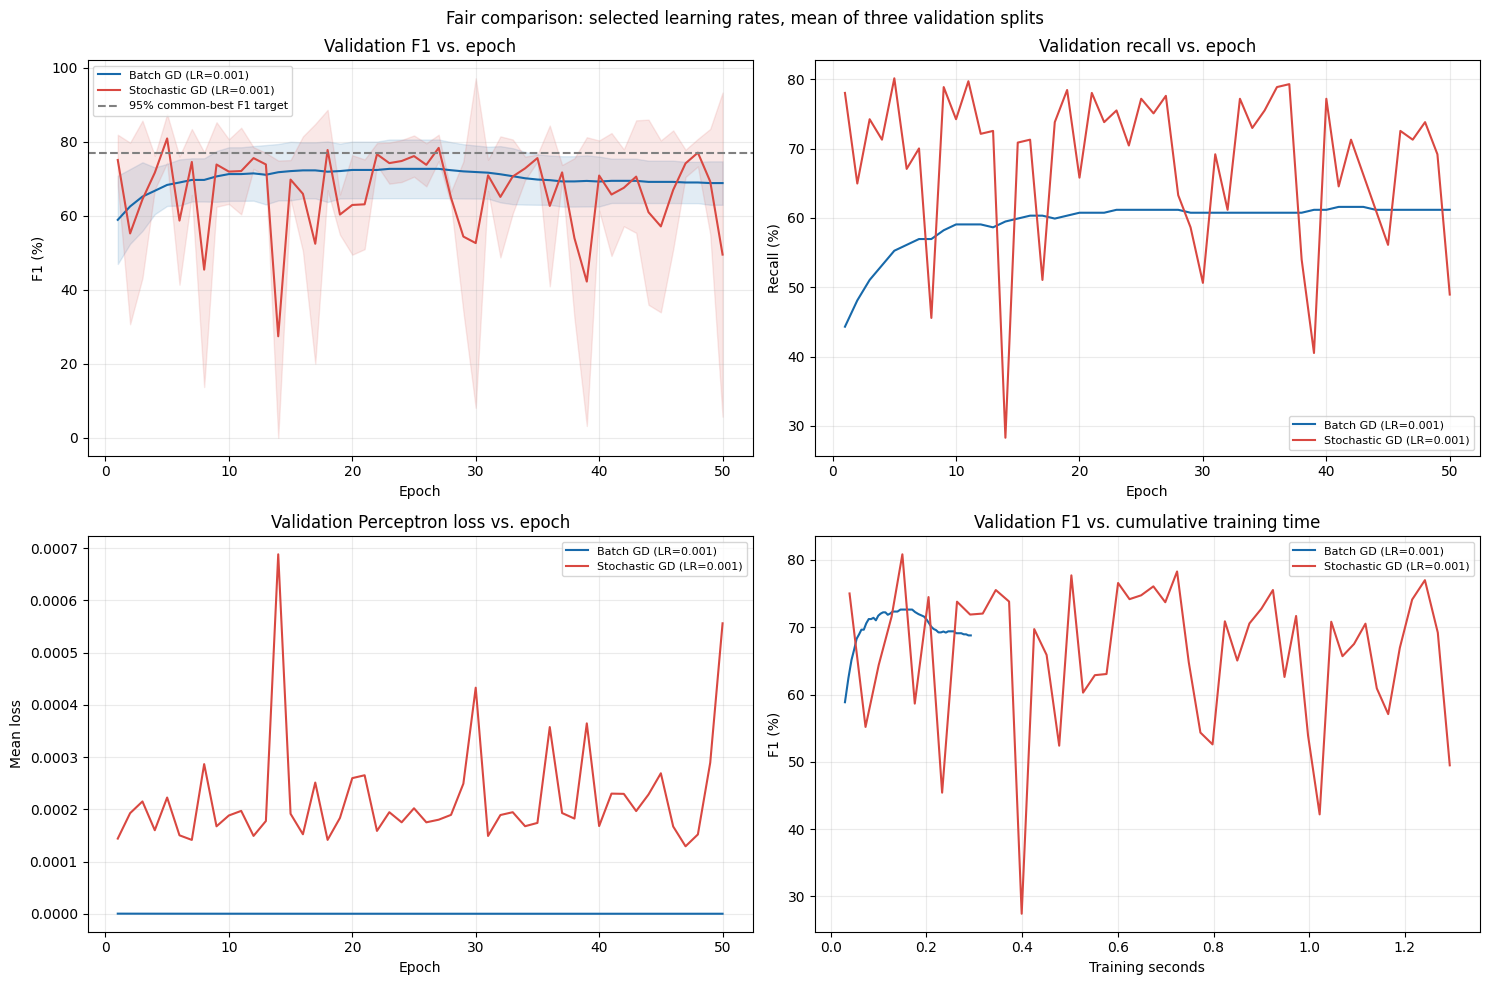

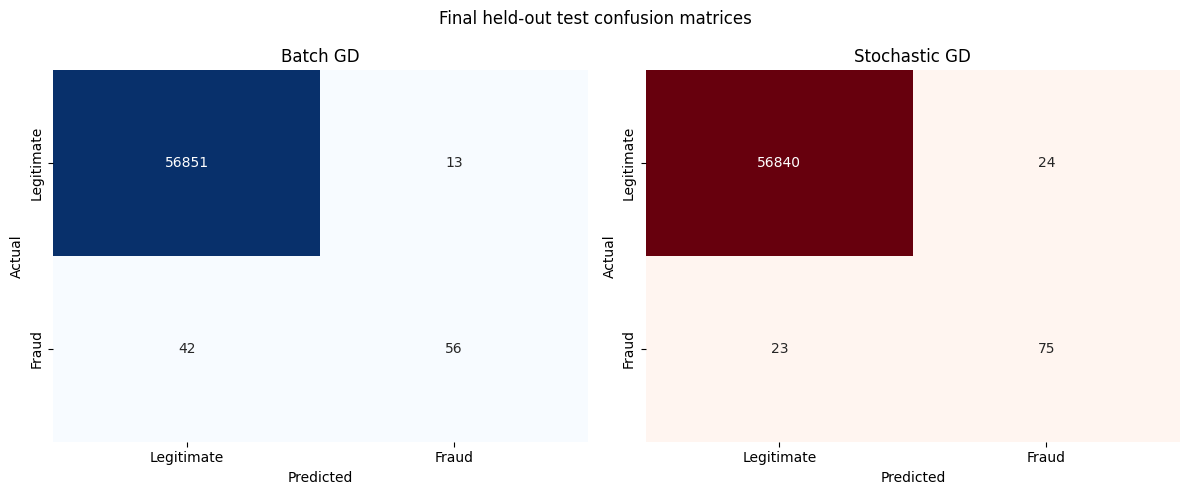

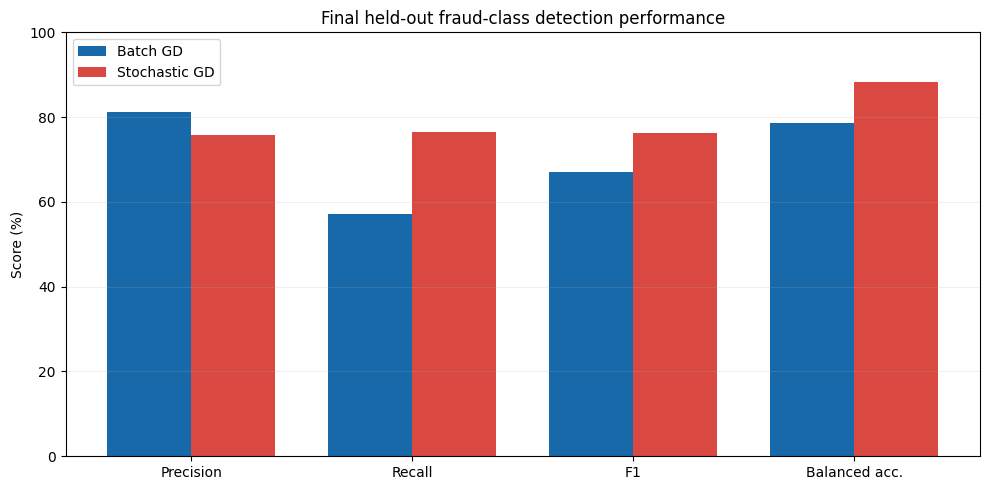


All figures, CSVs, models and settings saved to: /content/CreditCard_Fraud_Final/final_run_20261110T023225Z_2f440d
ZIP archive: /content/CreditCard_Fraud_Final/final_run_20261110T023225Z_2f440d.zip
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Google Drive backup completed: /content/drive/MyDrive/CreditCard_Fraud_Final/final_run_20261110T023225Z_2f440d

FINAL INTERPRETATION
Best threshold-specific test F1: Stochastic GD
Best threshold-free test PR-AUC: Batch GD
Shortest selected-model training time: Stochastic GD
Compare convergence curves for time-to-validation-target; do not equate
lowest total runtime with fastest convergence or best fraud detection.
FINAL CELL COMPLETE. No further code cells are required.


In [15]:

import json
import shutil
import time
import uuid
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from numba import njit
from sklearn import __version__ as sklearn_version
from sklearn.metrics import (
    accuracy_score, average_precision_score, balanced_accuracy_score,
    confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1) Reproducible configuration. Keep the original test partition.
SEED_TEST = 42
SEEDS_VALIDATION = (11, 23, 42)
LEARNING_RATES = (0.001, 0.01, 0.1, 1.0)
MAX_EPOCHS = 50
METHODS = ("Batch GD", "Stochastic GD")

if "X" not in globals() or "y" not in globals():
    raise RuntimeError("Run Cell 1 first: X and y must contain the ORIGINAL, unscaled dataset.")

X_raw = np.asarray(X, dtype=np.float64)
y_raw = np.asarray(y, dtype=np.int64).ravel()
if (X_raw.ndim != 2 or X_raw.shape[0] != len(y_raw)
        or not np.isfinite(X_raw).all()
        or not set(np.unique(y_raw)).issubset({0, 1})
        or len(np.unique(y_raw)) != 2):
    raise ValueError("Expected finite numerical X and binary y from the Credit Card dataset.")

X_dev, X_test_final, y_dev, y_test_final = train_test_split(
    X_raw, y_raw, test_size=0.2, random_state=SEED_TEST, stratify=y_raw
)
print("=" * 75)
print("FINAL EXPERIMENT: Credit Card Fraud - Batch GD vs. Stochastic GD")
print("=" * 75)
print(f"Samples: {len(y_raw):,} | Development: {len(y_dev):,} | "
      f"Test: {len(y_test_final):,} | Test fraud: {y_test_final.sum():,}")
print("Model selection uses only development/validation data; test is excluded.")

# 2) The SAME Perceptron loss and decision rule for both optimizers.
#    Batch: one full-dataset average update / epoch.
#    SGD: one sample update at a time, in a shuffled order / epoch.
@njit
def _sgd_one_epoch(X_in, signed_y, weights, bias, ordering, lr):
    n_features = X_in.shape[1]
    for i in ordering:
        score = bias
        for j in range(n_features):
            score += X_in[i, j] * weights[j]
        if signed_y[i] * score <= 0.0:
            for j in range(n_features):
                weights[j] += lr * signed_y[i] * X_in[i, j]
            bias += lr * signed_y[i]
    return bias

# Compile JIT before any timings (avoids charging compilation to SGD).
_s = np.zeros((4, X_raw.shape[1]), dtype=np.float64)
_ = _sgd_one_epoch(_s, np.array([-1, 1, -1, 1], dtype=np.int64),
                   np.zeros(X_raw.shape[1], dtype=np.float64), 0.0,
                   np.arange(4, dtype=np.int64), 0.1)

def train_with_history(method, features, target, lr, epochs, seed):
    features = np.ascontiguousarray(features, dtype=np.float64)
    signed_y = np.where(target == 1, 1, -1).astype(np.int64)
    n, d = features.shape
    weights = np.zeros(d, dtype=np.float64)
    bias = 0.0
    weights_history = np.empty((epochs, d), dtype=np.float64)
    biases_history = np.empty(epochs, dtype=np.float64)
    seconds_history = np.empty(epochs, dtype=np.float64)
    rng = np.random.default_rng(seed)
    start = time.perf_counter()

    for ep in range(epochs):
        if method == "Batch GD":
            scores = features @ weights + bias
            incorrect = (signed_y * scores <= 0.0)
            if np.any(incorrect):
                weights += lr * (features[incorrect].T @ signed_y[incorrect]) / n
                bias += lr * signed_y[incorrect].sum() / n
        else:
            ordering = rng.permutation(n).astype(np.int64)
            bias = _sgd_one_epoch(features, signed_y, weights, bias, ordering, lr)

        weights_history[ep] = weights
        biases_history[ep] = bias
        seconds_history[ep] = time.perf_counter() - start

    return weights_history, biases_history, seconds_history

def validation_curves(X_valid, y_valid, wh, bh):
    scores = X_valid @ wh.T + bh[None, :]
    predictions = scores >= 0.0
    positive = (y_valid == 1)[:, None]
    tp = np.sum(predictions & positive, axis=0)
    fp = np.sum(predictions & ~positive, axis=0)
    fn = y_valid.sum() - tp
    f1 = np.divide(2 * tp, 2 * tp + fp + fn,
                   out=np.zeros(len(tp), dtype=float),
                   where=(2 * tp + fp + fn) > 0)
    recall = tp / y_valid.sum()
    signed_y = np.where(y_valid == 1, 1.0, -1.0)
    loss = np.maximum(0.0, -signed_y[:, None] * scores).mean(axis=0)
    return {"f1": f1, "recall": recall, "loss": loss}

# 3) Three repeatable validation splits. Scale inside each split only.
folds = []
for split_seed in SEEDS_VALIDATION:
    Xa, Xv, ya, yv = train_test_split(
        X_dev, y_dev, test_size=0.2, random_state=split_seed,
        stratify=y_dev
    )
    fold_scaler = StandardScaler()
    Xa = np.ascontiguousarray(fold_scaler.fit_transform(Xa), dtype=np.float64)
    Xv = np.ascontiguousarray(fold_scaler.transform(Xv), dtype=np.float64)
    folds.append((Xa, Xv, ya, yv, split_seed))

# 4) Tune each optimizer on validation F1 ONLY; test stays out of tuning.
all_epoch_rows = []
candidates = {}
tuning_rows = []
for method in METHODS:
    for lr in LEARNING_RATES:
        runs = []
        for Xa, Xv, ya, yv, seed in folds:
            wh, bh, elapsed = train_with_history(
                method, Xa, ya, lr, MAX_EPOCHS, seed
            )
            curves = validation_curves(Xv, yv, wh, bh)
            runs.append({**curves, "seconds": elapsed})
            for ep in range(MAX_EPOCHS):
                all_epoch_rows.append({
                    "Method": method, "Learning Rate": lr, "Split Seed": seed,
                    "Epoch": ep + 1, "Validation F1": float(curves["f1"][ep]),
                    "Validation Recall": float(curves["recall"][ep]),
                    "Validation Perceptron Loss": float(curves["loss"][ep]),
                    "Cumulative Training Seconds": float(elapsed[ep])
                })

        means = {key: np.mean([r[key] for r in runs], axis=0)
                 for key in ("f1", "recall", "loss", "seconds")}
        f1_std = np.std([r["f1"] for r in runs], axis=0, ddof=1)
        best_idx = int(np.argmax(means["f1"]))
        candidates[(method, lr)] = {
            **means, "f1_std": f1_std,
            "best_epoch": best_idx + 1,
            "best_mean_f1": float(means["f1"][best_idx])
        }
        tuning_rows.append({
            "Method": method, "Learning Rate": lr,
            "Best Epoch": best_idx + 1,
            "Best Mean Validation F1": float(means["f1"][best_idx]),
            "Validation F1 SD at Best Epoch": float(f1_std[best_idx]),
            "Mean Training Seconds at Best Epoch": float(means["seconds"][best_idx])
        })
        print(f"{method:<16} LR={lr:<6g} | best mean val F1="
              f"{means['f1'][best_idx]:.4f} at epoch {best_idx+1}")

chosen = {}
for method in METHODS:
    possibilities = [(lr, candidates[(method, lr)]) for lr in LEARNING_RATES]
    best_lr, best_run = max(
        possibilities, key=lambda p: (p[1]["best_mean_f1"], -p[1]["best_epoch"])
    )
    chosen[method] = {"lr": best_lr, **best_run}

# 5) Convergence milestones; common target and each method's own target.
common_target = 0.95 * max(chosen[m]["best_mean_f1"] for m in METHODS)
convergence_rows = []
def first_at_or_above(curve, target):
    idx = np.flatnonzero(curve >= target)
    return int(idx[0]) if len(idx) else None

for method in METHODS:
    c = chosen[method]
    common_idx = first_at_or_above(c["f1"], common_target)
    own_idx = first_at_or_above(c["f1"], 0.95 * c["best_mean_f1"])
    convergence_rows.append({
        "Method": method, "Chosen LR": c["lr"],
        "Chosen Epochs": c["best_epoch"],
        "Best Mean Validation F1": c["best_mean_f1"],
        "Mean Validation F1 SD": float(c["f1_std"].mean()),
        "Epoch to 95% Own Best F1": None if own_idx is None else own_idx + 1,
        "Epoch to 95% Common Best F1": None if common_idx is None else common_idx + 1,
        "Seconds to 95% Common Best F1": (
            None if common_idx is None else float(c["seconds"][common_idx])
        )
    })

# 6) Train the best validation-selected configuration once on ALL
#    development samples; evaluate the held-out test partition once.
scaler_final = StandardScaler()
X_dev_scaled = np.ascontiguousarray(
    scaler_final.fit_transform(X_dev), dtype=np.float64
)
X_test_scaled = np.ascontiguousarray(
    scaler_final.transform(X_test_final), dtype=np.float64
)
final_rows = []
final_preds = {"Actual Class": y_test_final}
final_confusions = {}
final_models = {}

for method in METHODS:
    c = chosen[method]
    wh, bh, timing = train_with_history(
        method, X_dev_scaled, y_dev, c["lr"], c["best_epoch"], seed=42
    )
    weights, bias = wh[-1], float(bh[-1])
    score = X_test_scaled @ weights + bias
    predicted = (score >= 0.0).astype(int)  # same rule as Cells 3-6
    cm = confusion_matrix(y_test_final, predicted, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    final_confusions[method] = cm
    final_models[method] = (weights, bias)
    final_preds[f"{method} score"] = score
    final_preds[f"{method} prediction"] = predicted
    final_rows.append({
        "Method": method, "Learning Rate": c["lr"],
        "Epochs": c["best_epoch"], "Train Time (s)": timing[-1],
        "Accuracy (%)": 100 * accuracy_score(y_test_final, predicted),
        "Precision (%)": 100 * precision_score(y_test_final, predicted, zero_division=0),
        "Recall (%)": 100 * recall_score(y_test_final, predicted, zero_division=0),
        "F1 (%)": 100 * f1_score(y_test_final, predicted, zero_division=0),
        "Balanced Accuracy (%)": 100 * balanced_accuracy_score(y_test_final, predicted),
        "PR-AUC (Avg Precision)": average_precision_score(y_test_final, score),
        "ROC-AUC": roc_auc_score(y_test_final, score),
        "Fraud Detected (TP)": int(tp), "Fraud Missed (FN)": int(fn),
        "False Alarms (FP)": int(fp), "True Negatives (TN)": int(tn)
    })

comparison = pd.DataFrame(final_rows)
convergence = pd.DataFrame(convergence_rows)
tuning = pd.DataFrame(tuning_rows)
print("\n" + "=" * 75)
print("FINAL TEST RESULTS - validation-tuned, threshold fixed at score >= 0")
print("=" * 75)
print(comparison.round(4).to_string(index=False))
print("\nCONVERGENCE RESULTS - across 3 validation splits")
print(convergence.round(4).to_string(index=False))

# 7) Visualizations: learning curves, fairness over time, test confusion.
fig, ax = plt.subplots(2, 2, figsize=(15, 10))
epoch_axis = np.arange(1, MAX_EPOCHS + 1)
colors = {"Batch GD": "#1769aa", "Stochastic GD": "#d94841"}
for method in METHODS:
    c = chosen[method]
    clr = colors[method]
    label = f"{method} (LR={c['lr']:g})"
    ax[0, 0].plot(epoch_axis, 100 * c["f1"], label=label, color=clr)
    ax[0, 0].fill_between(
        epoch_axis, 100 * np.maximum(c["f1"] - c["f1_std"], 0),
        100 * np.minimum(c["f1"] + c["f1_std"], 1),
        color=clr, alpha=0.12
    )
    ax[0, 1].plot(epoch_axis, 100 * c["recall"], label=label, color=clr)
    ax[1, 0].plot(epoch_axis, c["loss"], label=label, color=clr)
    ax[1, 1].plot(c["seconds"], 100 * c["f1"], label=label, color=clr)
ax[0, 0].axhline(100 * common_target, color="gray", ls="--",
                 label="95% common-best F1 target")
for axes, title, xlabel, ylabel in [
    (ax[0, 0], "Validation F1 vs. epoch", "Epoch", "F1 (%)"),
    (ax[0, 1], "Validation recall vs. epoch", "Epoch", "Recall (%)"),
    (ax[1, 0], "Validation Perceptron loss vs. epoch", "Epoch", "Mean loss"),
    (ax[1, 1], "Validation F1 vs. cumulative training time", "Training seconds", "F1 (%)")
]:
    axes.set_title(title)
    axes.set_xlabel(xlabel)
    axes.set_ylabel(ylabel)
    axes.grid(alpha=0.25)
    axes.legend(fontsize=8)
fig.suptitle("Fair comparison: selected learning rates, mean of three validation splits")
fig.tight_layout()

fig_cm, ax_cm = plt.subplots(1, 2, figsize=(12, 5))
for axis, method in zip(ax_cm, METHODS):
    sns.heatmap(final_confusions[method], annot=True, fmt="d",
                cmap="Blues" if method == "Batch GD" else "Reds",
                xticklabels=["Legitimate", "Fraud"],
                yticklabels=["Legitimate", "Fraud"],
                cbar=False, ax=axis)
    axis.set_title(method)
    axis.set_xlabel("Predicted")
    axis.set_ylabel("Actual")
fig_cm.suptitle("Final held-out test confusion matrices")
fig_cm.tight_layout()

fig_perf, ax_perf = plt.subplots(figsize=(10, 5))
metrics_to_plot = ["Precision (%)", "Recall (%)", "F1 (%)", "Balanced Accuracy (%)"]
xx = np.arange(len(metrics_to_plot))
for index, method in enumerate(METHODS):
    vals = comparison.loc[comparison["Method"] == method, metrics_to_plot].iloc[0]
    ax_perf.bar(xx + (index - 0.5) * 0.38, vals.to_numpy(dtype=float),
                width=0.38, label=method, color=colors[method])
ax_perf.set_xticks(xx, ["Precision", "Recall", "F1", "Balanced acc."])
ax_perf.set_ylim(0, 100)
ax_perf.set_ylabel("Score (%)")
ax_perf.set_title("Final held-out fraud-class detection performance")
ax_perf.legend()
ax_perf.grid(axis="y", alpha=0.2)
fig_perf.tight_layout()

# 8) Save all results, figures and trained model parameters without overwrites.
run_id = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ") + "_" + uuid.uuid4().hex[:6]
root = Path("/content/CreditCard_Fraud_Final") if Path("/content").exists() else Path.cwd() / "CreditCard_Fraud_Final"
run_dir = root / f"final_run_{run_id}"
run_dir.mkdir(parents=True, exist_ok=False)

pd.DataFrame(all_epoch_rows).to_csv(run_dir / "all_validation_epochs.csv", index=False)
tuning.to_csv(run_dir / "learning_rate_tuning.csv", index=False)
convergence.to_csv(run_dir / "convergence_summary.csv", index=False)
comparison.to_csv(run_dir / "final_test_metrics.csv", index=False)
pd.DataFrame(final_preds).to_csv(run_dir / "final_test_predictions.csv", index=False)
fig.savefig(run_dir / "convergence_curves.png", dpi=200, bbox_inches="tight")
fig_cm.savefig(run_dir / "confusion_matrices.png", dpi=200, bbox_inches="tight")
fig_perf.savefig(run_dir / "test_metric_comparison.png", dpi=200, bbox_inches="tight")
plt.show()

for method in METHODS:
    w, b = final_models[method]
    np.savez(run_dir / f"{method.lower().replace(' ', '_')}_model.npz",
             weights=w, bias=b,
             scaler_mean=scaler_final.mean_, scaler_scale=scaler_final.scale_,
             learning_rate=chosen[method]["lr"], epochs=chosen[method]["best_epoch"])

metadata = {
    "dataset": "https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud",
    "split": "Outer stratified 80/20, random_state=42; inner 80/20 of development",
    "validation_seeds": SEEDS_VALIDATION,
    "learning_rates": LEARNING_RATES,
    "max_epochs": MAX_EPOCHS,
    "selection": "Maximize mean validation F1 across three splits over learning rate and epoch",
    "threshold": "Perceptron signed decision score >= 0; not tuned",
    "numpy_version": np.__version__,
    "sklearn_version": sklearn_version,
    "final_configs": {m: {"lr": chosen[m]["lr"], "epochs": chosen[m]["best_epoch"]}
                      for m in METHODS},
    "caveats": [
        "The original test partition was viewed in earlier cells; results are exploratory.",
        "Batch and SGD use the same Perceptron loss but different update frequency.",
        "With zero initialization, positive learning rates primarily rescale Perceptron weights; learning-rate tuning may not change classification predictions.",
        "Time-to-F1-target is an empirical milestone, not proof of mathematical convergence.",
        "PR-AUC is average precision using signed decision scores, not calibrated probabilities."
    ]
}
(run_dir / "experiment_metadata.json").write_text(
    json.dumps(metadata, indent=2), encoding="utf-8"
)
# Export a short, self-contained report alongside raw results.
batch_row = comparison.loc[comparison["Method"] == "Batch GD"].iloc[0]
sgd_row = comparison.loc[comparison["Method"] == "Stochastic GD"].iloc[0]
report_text = f"""# Credit Card Fraud Detection - Final Comparative Report

Dataset: https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud
Samples: {len(y_raw):,}; held-out test: {len(y_test_final):,}; fraudulent test cases: {int(y_test_final.sum())}.

## Experiment
Same original 80/20 stratified partition (seed 42). The 80% development set
was split three ways for validation (seeds {SEEDS_VALIDATION}). Each method
was evaluated over {MAX_EPOCHS} epochs and learning rates {LEARNING_RATES}.
Learning rate and stopping epoch were chosen by best mean validation F1.
Models were then refitted to all development data and evaluated on the same
test partition with a fixed signed-score threshold of zero.

## Test results
Batch GD: accuracy {batch_row['Accuracy (%)']:.4f}%, precision {batch_row['Precision (%)']:.4f}%,
recall {batch_row['Recall (%)']:.4f}%, F1 {batch_row['F1 (%)']:.4f}%,
PR-AUC {batch_row['PR-AUC (Avg Precision)']:.4f}; detected {int(batch_row['Fraud Detected (TP)'])} frauds;
missed {int(batch_row['Fraud Missed (FN)'])}; train time {batch_row['Train Time (s)']:.4f}s.

Stochastic GD: accuracy {sgd_row['Accuracy (%)']:.4f}%, precision {sgd_row['Precision (%)']:.4f}%,
recall {sgd_row['Recall (%)']:.4f}%, F1 {sgd_row['F1 (%)']:.4f}%,
PR-AUC {sgd_row['PR-AUC (Avg Precision)']:.4f}; detected {int(sgd_row['Fraud Detected (TP)'])} frauds;
missed {int(sgd_row['Fraud Missed (FN)'])}; train time {sgd_row['Train Time (s)']:.4f}s.

## Interpretation and limitations
Time-to-F1 target measures how fast a validation quality milestone was reached;
it does not prove mathematical convergence. Training time is a separate
measure. Three development splits offer limited stability evidence, not an
independent external validation. Because the test split was already viewed in
earlier notebook cells, this is an exploratory comparison rather than a new
confirmatory blinded test. PR-AUC uses signed decision scores (not probabilities).
A standard zero-initialized Perceptron is largely invariant to positive changes
in learning rate because the parameter vector scales with the learning rate.
"""
(run_dir / "FINAL_REPORT.md").write_text(report_text, encoding="utf-8")

zip_path = Path(shutil.make_archive(str(run_dir), "zip",
                                    root_dir=run_dir.parent, base_dir=run_dir.name))
print(f"\nAll figures, CSVs, models and settings saved to: {run_dir}")
print(f"ZIP archive: {zip_path}")

# Copy to Google Drive automatically in Colab (authorization may be needed).
try:
    from google.colab import drive
    drive.mount("/content/drive")
    drive_root = Path("/content/drive/MyDrive/CreditCard_Fraud_Final")
    drive_root.mkdir(parents=True, exist_ok=True)
    dest = drive_root / run_dir.name
    shutil.copytree(run_dir, dest)
    shutil.copy2(zip_path, drive_root / zip_path.name)
    print(f"Google Drive backup completed: {dest}")
except (ImportError, Exception) as err:
    print("Google Drive backup unavailable; local files and ZIP were saved.")
    print("Reason:", str(err)[:200])

best_f1_method = comparison.loc[comparison["F1 (%)"].idxmax(), "Method"]
best_pr_method = comparison.loc[comparison["PR-AUC (Avg Precision)"].idxmax(), "Method"]
fastest_method = comparison.loc[comparison["Train Time (s)"].idxmin(), "Method"]
print("\n" + "=" * 75)
print("FINAL INTERPRETATION")
print("=" * 75)
print(f"Best threshold-specific test F1: {best_f1_method}")
print(f"Best threshold-free test PR-AUC: {best_pr_method}")
print(f"Shortest selected-model training time: {fastest_method}")
print("Compare convergence curves for time-to-validation-target; do not equate")
print("lowest total runtime with fastest convergence or best fraud detection.")
print("FINAL CELL COMPLETE. No further code cells are required.")
